# Molecular subtypes and prognostic genes in breast cancer: what the labels already know

**Data:** TCGA-BRCA from UCSC Xena --- 20,530 genes across 1,218 samples (1,101 primary tumours,
139 adjacent normals), with PAM50 subtype calls, tissue source site and survival follow-up.

**Questions**
1. Which genes separate tumour from adjacent normal tissue, and which pathways do they fall in?
2. How well can PAM50 subtype be predicted from expression --- and **how much of that is
   circular**, given that the PAM50 label is itself computed from this expression matrix?
3. Does performance survive grouping the folds by **tissue source site**, the batch variable in
   TCGA?
4. Does an expression signature add prognostic information beyond stage and age, once gene
   selection is done inside the training folds rather than on the whole cohort?

Runs in Colab or Kaggle. Downloads ~65 MB from UCSC Xena on first run.

In [1]:
import os, sys, io, json, gzip, time, warnings, subprocess, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
try:
    from lifelines import CoxPHFitter, KaplanMeierFitter
    from lifelines.statistics import multivariate_logrank_test, logrank_test
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lifelines"])
    from lifelines import CoxPHFitter, KaplanMeierFitter
    from lifelines.statistics import multivariate_logrank_test, logrank_test
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, matthews_corrcoef)

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110, "savefig.dpi": 300})
SEED = 42
ON_KAGGLE = os.path.isdir("/kaggle/working")
BASE = "/kaggle/working" if ON_KAGGLE else "."
FIG, RES = f"{BASE}/figures", f"{BASE}/results"
os.makedirs(FIG, exist_ok=True); os.makedirs(RES, exist_ok=True)

SUBTYPES = ["LumA", "LumB", "Her2", "Basal"]   # Normal-like excluded: see Section 2
SCOL = {"LumA": "#1F5F8B", "LumB": "#4FA3D1", "Her2": "#8E44AD", "Basal": "#C2185B",
        "Normal": "#7F8C8D"}
N_TOP_VAR = 2000          # most variable genes retained for modelling
N_REP = 3

# The 50 PAM50 genes (Parker et al., J Clin Oncol 2009). Older TCGA symbols are listed alongside.
PAM50 = """ACTR3B ANLN BAG1 BCL2 BIRC5 BLVRA CCNB1 CCNE1 CDC20 CDC6 CDH3 CENPF CEP55 CXXC5 EGFR
ERBB2 ESR1 EXO1 FGFR4 FOXA1 FOXC1 GPR160 GRB7 KIF2C KRT14 KRT17 KRT5 MAPT MDM2 MELK MIA MKI67 MLPH
MMP11 MYBL2 MYC NAT1 NDC80 NUF2 ORC6 PGR PHGDH PTTG1 RRM2 SFRP1 SLC39A6 TMEM45B TYMS UBE2C
UBE2T""".split()
PAM50_ALIASES = {"NDC80": "KNTC2", "ORC6": "ORC6L", "NUF2": "CDCA1", "CEP55": "C10orf3",
                 "TMEM45B": "TMEM45B", "KIF2C": "KIF2C"}

## 1. Download and load

In [2]:
HUB = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download"
FILES = {"HiSeqV2.gz": "TCGA.BRCA.sampleMap%2FHiSeqV2.gz",
         "BRCA_clinicalMatrix": "TCGA.BRCA.sampleMap%2FBRCA_clinicalMatrix",
         "BRCA_survival.txt": "survival%2FBRCA_survival.txt"}

def locate(name):
    for p in (f"/kaggle/input/tcga-brca-xena/{name}", f"data/{name}", name):
        if os.path.exists(p):
            return p
    import glob
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if hits:
        return hits[0]
    os.makedirs("data", exist_ok=True)
    dest = f"data/{name}"
    print(f"  downloading {name} ...", flush=True)
    urllib.request.urlretrieve(f"{HUB}/{FILES[name]}", dest)
    return dest

t0 = time.time()
expr = pd.read_csv(locate("HiSeqV2.gz"), sep="\t", index_col=0)      # log2(RSEM norm_count + 1)
clin = pd.read_csv(locate("BRCA_clinicalMatrix"), sep="\t", low_memory=False).set_index("sampleID")
surv = pd.read_csv(locate("BRCA_survival.txt"), sep="\t").set_index("sample")
print(f"expression {expr.shape[0]:,} genes x {expr.shape[1]:,} samples  ({time.time()-t0:.0f}s)")

expression 20,530 genes x 1,218 samples  (1s)


## 2. Sample annotation
Tissue source site is the two-character block in the barcode (TCGA-**BH**-A0B3-01) and identifies
the hospital that contributed the sample. It is the natural batch variable in TCGA and is used
below as the grouping factor, in the same role that source publication played in the two
companion analyses.

In [3]:
common = expr.columns.intersection(clin.index)
expr = expr[common]
meta = pd.DataFrame(index=common)
meta["sample_type"] = clin.loc[common, "sample_type"]
meta["pam50"] = clin.loc[common, "PAM50Call_RNAseq"]
meta["tss"] = [s.split("-")[1] for s in common]
meta["patient"] = ["-".join(s.split("-")[:3]) for s in common]
meta["age"] = pd.to_numeric(clin.loc[common, "age_at_initial_pathologic_diagnosis"], errors="coerce")
stage = clin.loc[common, "pathologic_stage"].astype(str)
meta["stage"] = (stage.str.replace("Stage ", "", regex=False)
                      .str.replace(r"[ABC]$", "", regex=True)
                      .replace({"nan": np.nan, "X": np.nan, "Tis": np.nan}))
meta["is_tumour"] = meta.sample_type.eq("Primary Tumor")

print(meta.sample_type.value_counts().to_string())
print(f"\ntissue source sites: {meta.tss.nunique()}  |  patients: {meta.patient.nunique()}")
tum = meta[meta.is_tumour].copy()
n_normal_like = int(tum.pam50.eq("Normal").sum())
lab = tum[tum.pam50.isin(SUBTYPES)]
print(f"\nNormal-like calls among primary tumours: {n_normal_like} - excluded from modelling, as "
      "this class is widely regarded as reflecting normal-tissue contamination rather than a "
      "distinct tumour biology, and the count is too small for grouped folds")
print(f"PAM50-labelled tumours retained: {len(lab):,}")
print(lab.pam50.value_counts().reindex(SUBTYPES).to_string())

cohort = pd.DataFrame({
    "Primary tumours": [int(meta.is_tumour.sum())],
    "Adjacent normals": [int(meta.sample_type.eq("Solid Tissue Normal").sum())],
    "Genes measured": [expr.shape[0]],
    "Tissue source sites": [meta.tss.nunique()],
    "PAM50-labelled tumours": [len(lab)],
    **{f"  {s}": [int((lab.pam50 == s).sum())] for s in SUBTYPES}}).T
cohort.columns = ["n"]
cohort.to_csv(f"{RES}/Table1_cohort.csv")
cohort

sample_type
Primary Tumor          1097
Solid Tissue Normal     114
Metastatic                7

tissue source sites: 40  |  patients: 1097

Normal-like calls among primary tumours: 23 - excluded from modelling, as this class is widely regarded as reflecting normal-tissue contamination rather than a distinct tumour biology, and the count is too small for grouped folds
PAM50-labelled tumours retained: 821
pam50
LumA     421
LumB     192
Her2      67
Basal    141


,n
Primary tumours,1097
Adjacent normals,114
Genes measured,20530
Tissue source sites,40
PAM50-labelled tumours,821
LumA,421
LumB,192
Her2,67
Basal,141


## 3. Tumour against adjacent normal tissue

In [4]:
tcols = meta.index[meta.is_tumour]
ncols = meta.index[meta.sample_type.eq("Solid Tissue Normal")]
# 280 genes are flat in both groups; they yield NaN p-values that would poison the FDR step
keep_var = (expr[tcols].values.std(axis=1) > 0) | (expr[ncols].values.std(axis=1) > 0)
print(f"dropping {int((~keep_var).sum())} genes with zero variance in both groups")
expr_de = expr[keep_var]
A, B = expr_de[tcols].values, expr_de[ncols].values
t, p = stats.ttest_ind(A, B, axis=1, equal_var=False)
ok = np.isfinite(p)
A, B, t, p = A[ok], B[ok], t[ok], p[ok]
expr_de = expr_de[ok]
lfc = A.mean(axis=1) - B.mean(axis=1)                 # already log2 scale
order = np.argsort(p)
q = np.empty_like(p); n = len(p)
q[order] = np.minimum.accumulate((p[order] * n / np.arange(1, n + 1))[::-1])[::-1]
de = pd.DataFrame({"gene": expr_de.index, "log2FC": lfc, "t": t, "p": p, "q": q}).set_index("gene")
de["direction"] = np.where(de.log2FC > 0, "up in tumour", "down in tumour")
sig = de[(de.q < 0.01) & (de.log2FC.abs() > 1)]
print(f"{len(sig):,} genes with FDR < 1% and |log2FC| > 1 "
      f"({(sig.log2FC > 0).sum():,} up, {(sig.log2FC < 0).sum():,} down)")
de.sort_values("q").head(40).round(4).to_csv(f"{RES}/Table2_tumour_vs_normal_top40.csv")
de.sort_values("q").head(12).round(3)

dropping 280 genes with zero variance in both groups


4,231 genes with FDR < 1% and |log2FC| > 1 (1,416 up, 2,815 down)


,log2FC,t,p,q,direction
gene,,,,,
MATN2,-3.445,-53.340,0.0,0.0,down in tumour
IBSP,4.182,51.022,0.0,0.0,up in tumour
SPRY2,-2.883,-58.522,0.0,0.0,down in tumour
NTRK2,-4.182,-50.747,0.0,0.0,down in tumour
SCN4B,-3.134,-52.750,0.0,0.0,down in tumour
ANKRD29,-3.014,-47.596,0.0,0.0,down in tumour
GSPT2,-1.655,-35.610,0.0,0.0,down in tumour
HOXA7,-2.833,-44.931,0.0,0.0,down in tumour
IL33,-3.908,-43.994,0.0,0.0,down in tumour


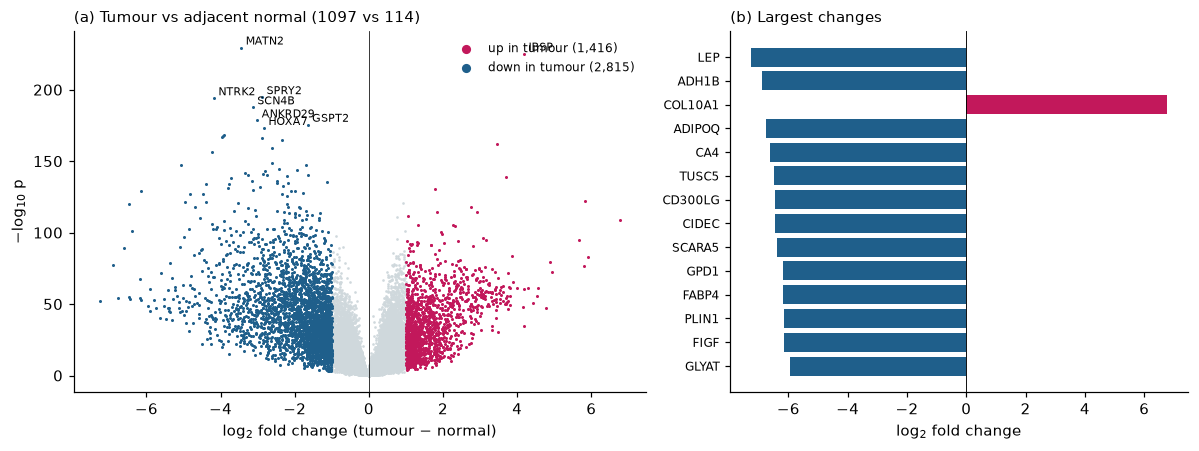

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axs[0]
nl = -np.log10(np.clip(de.p.values, 1e-300, None))
hit = (de.q < 0.01).values & (de.log2FC.abs() > 1).values
ax.scatter(de.log2FC[~hit], nl[~hit], s=3, color="#CFD8DC", lw=0)
ax.scatter(de.log2FC[hit & (de.log2FC > 0)], nl[hit & (de.log2FC > 0)], s=4, color="#C2185B", lw=0,
           label=f"up in tumour ({(hit & (de.log2FC>0).values).sum():,})")
ax.scatter(de.log2FC[hit & (de.log2FC < 0)], nl[hit & (de.log2FC < 0)], s=4, color="#1F5F8B", lw=0,
           label=f"down in tumour ({(hit & (de.log2FC<0).values).sum():,})")
for g in de[hit].sort_values("q").head(8).index:
    ax.annotate(g, (de.log2FC[g], nl[de.index.get_loc(g)]), fontsize=7,
                xytext=(3, 2), textcoords="offset points")
ax.axvline(0, color="k", lw=.5); ax.set_xlabel("log$_2$ fold change (tumour − normal)")
ax.set_ylabel("−log$_{10}$ p"); ax.legend(fontsize=8, frameon=False, markerscale=3)
ax.set_title(f"(a) Tumour vs adjacent normal ({len(tcols)} vs {len(ncols)})", fontsize=9.5, loc="left")

ax = axs[1]
top = de[hit].reindex(de[hit].log2FC.abs().sort_values(ascending=False).index).head(14).iloc[::-1]
ax.barh(range(len(top)), top.log2FC, color=[("#C2185B" if v > 0 else "#1F5F8B") for v in top.log2FC])
ax.set_yticks(range(len(top)), top.index, fontsize=8)
ax.axvline(0, color="k", lw=.6); ax.set_xlabel("log$_2$ fold change")
ax.set_title("(b) Largest changes", fontsize=9.5, loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig1_tumour_vs_normal.png"); plt.show()

## 4. Gene panel for modelling
The 5,000 most variable genes across tumours, together with the PAM50 genes, keep the models
tractable. Keeping the PAM50 genes explicit is what makes the circularity test in Section 5
possible.

In [6]:
tum_expr = expr[tum.index]
var_rank = tum_expr.var(axis=1).sort_values(ascending=False)
panel = list(var_rank.head(N_TOP_VAR).index)
present_pam50 = [g for g in PAM50 if g in expr.index]
missing = [g for g in PAM50 if g not in expr.index]
for g in missing:                                      # try the legacy symbol
    alias = PAM50_ALIASES.get(g)
    if alias and alias in expr.index:
        present_pam50.append(alias)
panel = sorted(set(panel) | set(present_pam50))
print(f"PAM50 genes found in the matrix: {len(present_pam50)}/50")
print(f"panel: {len(panel):,} genes ({len(set(panel) & set(present_pam50))} of them PAM50 genes)")

X_all = expr.loc[panel, lab.index].T.astype(np.float32)
X_nop = X_all.drop(columns=[g for g in present_pam50 if g in X_all.columns])
y = lab.pam50.values
groups = lab.tss.values
print(f"design matrix {X_all.shape} | without PAM50 genes {X_nop.shape}")

PAM50 genes found in the matrix: 50/50
panel: 2,030 genes (50 of them PAM50 genes)
design matrix (821, 2030) | without PAM50 genes (821, 1980)


## 5. Predicting PAM50 subtype: circularity and batch
Two factors are varied independently:

* **Gene set** --- all panel genes, or the panel with the 50 PAM50 genes removed. The PAM50 call
  is a nearest-centroid assignment computed from those 50 genes, so a model given them is partly
  re-deriving a deterministic function rather than learning biology.
* **Split** --- stratified random folds, or folds grouped by tissue source site so that a whole
  contributing hospital is held out.

In [7]:
def models():
    return {"LASSO (multinomial)": make_pipeline(
                StandardScaler(),
                LogisticRegression(penalty="l1", C=0.05, solver="saga", max_iter=1500,
                                   tol=1e-3, random_state=SEED)),
            "Random forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                                    max_features="sqrt", n_jobs=-1,
                                                    class_weight="balanced", random_state=SEED)}

def folds(scheme, X, yy, gg, seed):
    if scheme == "Random":
        return StratifiedKFold(5, shuffle=True, random_state=seed).split(X, yy)
    return StratifiedGroupKFold(5, shuffle=True, random_state=seed).split(X, yy, gg)

rows, store = [], {}
t0 = time.time()
for geneset, X in (("All genes", X_all), ("PAM50 genes removed", X_nop)):
    for scheme in ("Random", "Site-grouped"):
        for mname in models():
            for rep in range(N_REP):
                pred = np.empty(len(y), dtype=object)
                for tr, te in folds(scheme, X.values, y, groups, rep):
                    m = models()[mname].fit(X.values[tr], y[tr])
                    pred[te] = m.predict(X.values[te])
                rows.append({"Gene set": geneset, "Split": scheme, "Model": mname, "Repeat": rep,
                             "Balanced acc.": balanced_accuracy_score(y, pred),
                             "Macro F1": f1_score(y, pred, average="macro"),
                             "MCC": matthews_corrcoef(y, pred)})
                if rep == 0:
                    store[(geneset, scheme, mname)] = pred.copy()
        print(f"  {geneset} / {scheme} done ({time.time()-t0:.0f}s)", flush=True)
pam = pd.DataFrame(rows)
pam_sum = pam.groupby(["Gene set", "Split", "Model"])[["Balanced acc.", "Macro F1", "MCC"]].agg(["mean", "std"]).round(3)
pam_sum.columns = [f"{a} {b}" for a, b in pam_sum.columns]
pam_sum.to_csv(f"{RES}/Table3_pam50_classification.csv")
pam_sum

  All genes / Random done (134s)


  All genes / Site-grouped done (270s)


  PAM50 genes removed / Random done (366s)


  PAM50 genes removed / Site-grouped done (460s)


Balanced acc. mean  \
Gene set            Split        Model                                     
All genes           Random       LASSO (multinomial)               0.860   
                                 Random forest                     0.904   
                    Site-grouped LASSO (multinomial)               0.856   
                                 Random forest                     0.906   
PAM50 genes removed Random       LASSO (multinomial)               0.828   
                                 Random forest                     0.861   
                    Site-grouped LASSO (multinomial)               0.818   
                                 Random forest                     0.863   

                                                      Balanced acc. std  \
Gene set            Split        Model                                    
All genes           Random       LASSO (multinomial)              0.003   
                                 Random forest                    0.001   
                    Site-grouped LASSO (multinomial)              0.000   
                                 Random forest                    0.000   
PAM50 genes removed Random       LASSO (multinomial)              0.014   
                                 Random forest                    0.005   
                    Site-grouped LASSO (multinomial)              0.000   
                                 Random forest                    0.000   

                                                      Macro F1 mean  \
Gene set            Split        Model                                
All genes           Random       LASSO (multinomial)          0.877   
                                 Random forest                0.907   
                    Site-grouped LASSO (multinomial)          0.872   
                                 Random forest                0.906   
PAM50 genes removed Random       LASSO (multinomial)          0.848   
                                 Random forest                0.861   
                    Site-grouped LASSO (multinomial)          0.836   
                                 Random forest                0.859   

                                                      Macro F1 std  MCC mean  \
Gene set            Split        Model                                         
All genes           Random       LASSO (multinomial)         0.001     0.847   
                                 Random forest               0.000     0.869   
                    Site-grouped LASSO (multinomial)         0.000     0.844   
                                 Random forest               0.000     0.868   
PAM50 genes removed Random       LASSO (multinomial)         0.011     0.793   
                                 Random forest               0.005     0.786   
                    Site-grouped LASSO (multinomial)         0.000     0.780   
                                 Random forest               0.000     0.782   

                                                      MCC std  
Gene set            Split        Model                         
All genes           Random       LASSO (multinomial)    0.001  
                                 Random forest          0.001  
                    Site-grouped LASSO (multinomial)    0.000  
                                 Random forest          0.000  
PAM50 genes removed Random       LASSO (multinomial)    0.011  
                                 Random forest          0.008  
                    Site-grouped LASSO (multinomial)    0.000  
                                 Random forest          0.000

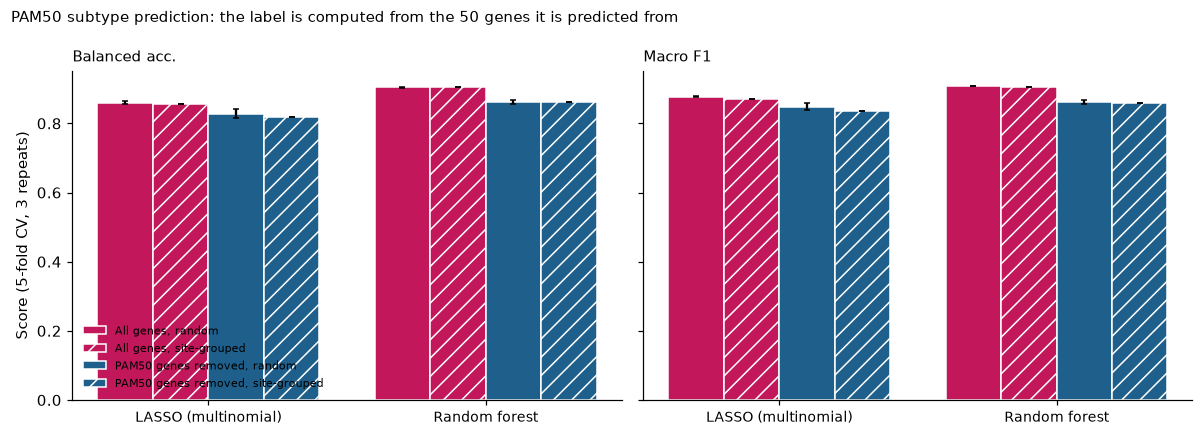

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric in zip(axs, ["Balanced acc.", "Macro F1"]):
    x = np.arange(2); w = 0.2
    for j, (gs, sch, c, hatch) in enumerate([
            ("All genes", "Random", "#C2185B", ""),
            ("All genes", "Site-grouped", "#C2185B", "//"),
            ("PAM50 genes removed", "Random", "#1F5F8B", ""),
            ("PAM50 genes removed", "Site-grouped", "#1F5F8B", "//")]):
        vals, errs = [], []
        for m in models():
            s = pam[(pam["Gene set"] == gs) & (pam.Split == sch) & (pam.Model == m)][metric]
            vals.append(s.mean()); errs.append(s.std())
        ax.bar(x + (j - 1.5) * w, vals, w, yerr=errs, capsize=2, color=c, hatch=hatch,
               edgecolor="w", label=f"{gs}, {sch.lower()}")
    ax.set_xticks(x, list(models()), fontsize=9)
    ax.set_title(metric, fontsize=10, loc="left")
axs[0].set_ylabel("Score (5-fold CV, 3 repeats)")
axs[0].legend(fontsize=7.5, frameon=False, loc="lower left")
fig.suptitle("PAM50 subtype prediction: the label is computed from the 50 genes it is predicted from",
             fontsize=10, x=.01, ha="left")
fig.tight_layout(); fig.savefig(f"{FIG}/Fig2_pam50_circularity.png"); plt.show()

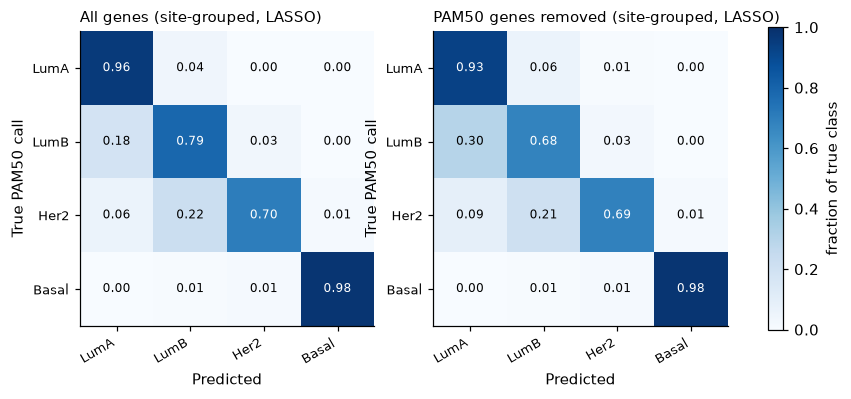

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, gs in zip(axs, ["All genes", "PAM50 genes removed"]):
    cm = confusion_matrix(y, store[(gs, "Site-grouped", "LASSO (multinomial)")],
                          labels=SUBTYPES, normalize="true")
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    k = len(SUBTYPES)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > .55 else "black")
    ax.set_xticks(range(k), SUBTYPES, fontsize=8.5, rotation=30, ha="right")
    ax.set_yticks(range(k), SUBTYPES, fontsize=8.5)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True PAM50 call")
    ax.set_title(f"{gs} (site-grouped, LASSO)", fontsize=9.5, loc="left")
fig.colorbar(im, ax=axs, shrink=.85, label="fraction of true class")
fig.savefig(f"{FIG}/Fig3_confusion.png", bbox_inches="tight"); plt.show()

## 6. The signature the LASSO selects

In [10]:
fit = models()["LASSO (multinomial)"].fit(X_nop.values, y)
coef = pd.DataFrame(fit[-1].coef_, index=fit[-1].classes_, columns=X_nop.columns)
nz = coef.loc[:, (coef != 0).any(axis=0)]
print(f"signature without PAM50 genes: {nz.shape[1]} genes carry a non-zero coefficient")
sig_tbl = []
for s in SUBTYPES:
    if s not in nz.index:
        continue
    top = nz.loc[s].sort_values(ascending=False).head(6)
    sig_tbl.append({"Subtype": s, "Top markers (positive weight)": ", ".join(top.index)})
sig_tbl = pd.DataFrame(sig_tbl)
sig_tbl.to_csv(f"{RES}/Table4_lasso_signature.csv", index=False)
nz.T.round(4).to_csv(f"{RES}/Table4b_signature_coefficients.csv")
sig_tbl

signature without PAM50 genes: 138 genes carry a non-zero coefficient


,Subtype,Top markers (positive weight)
0,LumA,"SCN2B, FAM189A2, LOC100128977, TAC1, STC2, PCSK6"
1,LumB,"RDH16, CYP2B7P1, KCNH1, DSCR6, FOXJ1, YBX2"
2,Her2,"PNMT, ATP13A5, MAGEC1, LOC150622, EPO, CLCA2"
3,Basal,"ROPN1, GDF5, LEMD1, AMY1A, FZD9, BPI"


## 7. Pathway enrichment of the tumour-vs-normal genes
Submitted to Enrichr; if the session has no internet the step is skipped and the analysis
continues.

In [11]:
def enrichr(genes, library="MSigDB_Hallmark_2020"):
    try:
        import requests
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "requests"]); import requests
    r = requests.post("https://maayanlab.cloud/Enrichr/addList",
                      files={"list": (None, "\n".join(genes)), "description": (None, "BRCA")}, timeout=60)
    uid = r.json()["userListId"]
    time.sleep(1)
    res = requests.get("https://maayanlab.cloud/Enrichr/enrich",
                       params={"userListId": uid, "backgroundType": library}, timeout=60).json()
    out = pd.DataFrame([{"Term": t[1], "p": t[2], "Odds ratio": t[3], "Combined score": t[4],
                         "Overlapping genes": len(t[5]), "q": t[6]} for t in res[library]])
    return out.sort_values("q")

enr = {}
try:
    for lab_, genes in (("Up in tumour", sig[sig.log2FC > 0].sort_values("q").head(300).index),
                        ("Down in tumour", sig[sig.log2FC < 0].sort_values("q").head(300).index)):
        enr[lab_] = enrichr(list(genes))
        print(f"{lab_}: {len(enr[lab_])} hallmark terms, {int((enr[lab_].q < .05).sum())} at FDR 5%")
    pd.concat({k: v.head(15) for k, v in enr.items()}).to_csv(f"{RES}/Table5_pathway_enrichment.csv")
except Exception as e:
    print("Enrichr unavailable, skipping pathway enrichment:", e)

Up in tumour: 38 hallmark terms, 7 at FDR 5%


Down in tumour: 38 hallmark terms, 2 at FDR 5%


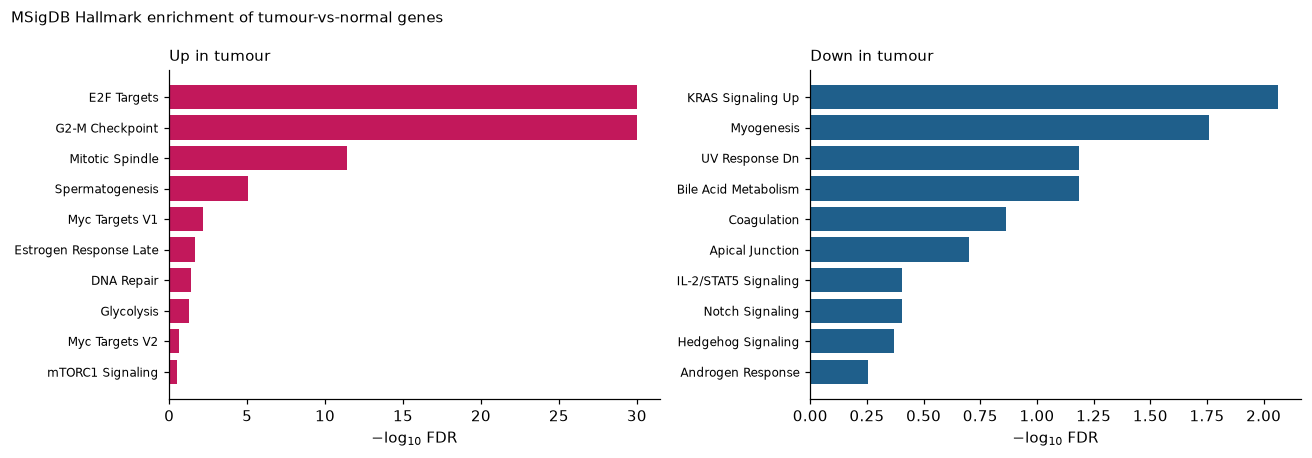

In [12]:
if enr:
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, (lab_, col) in zip(axs, (("Up in tumour", "#C2185B"), ("Down in tumour", "#1F5F8B"))):
        d_ = enr[lab_].head(10).iloc[::-1]
        ax.barh(range(len(d_)), -np.log10(d_.q.clip(lower=1e-30)), color=col)
        ax.set_yticks(range(len(d_)), [t[:42] for t in d_.Term], fontsize=8)
        ax.set_xlabel("−log$_{10}$ FDR"); ax.set_title(lab_, fontsize=9.5, loc="left")
    fig.suptitle("MSigDB Hallmark enrichment of tumour-vs-normal genes", fontsize=10, x=.01, ha="left")
    fig.tight_layout(); fig.savefig(f"{FIG}/Fig4_pathways.png"); plt.show()

## 8. Survival
Overall survival by PAM50 subtype, then the question that matters for a biomarker claim: does an
expression signature add prognostic information **beyond stage and age**? Genes are selected by
univariate Cox screening **inside each training fold**, so the held-out risk score is not
contaminated by selection on the full cohort.

809 tumours with survival follow-up | 120 deaths (14.8%) | median follow-up 32 months


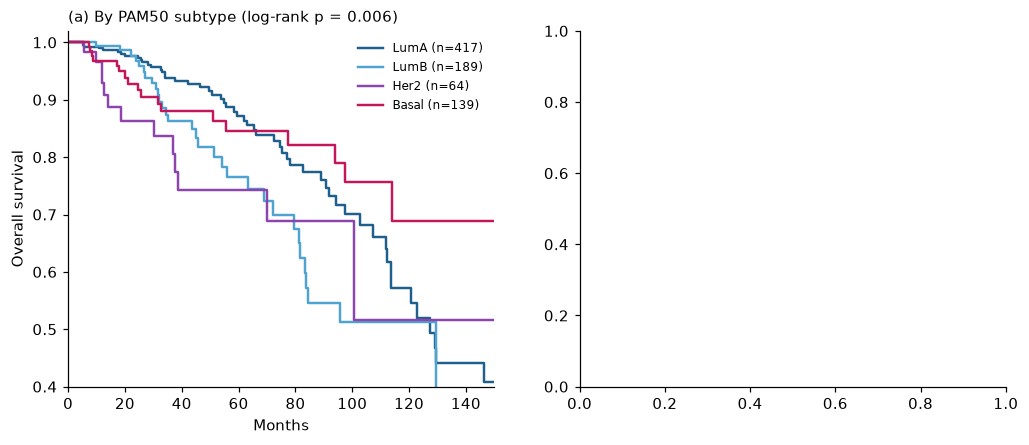

In [13]:
sv = surv.reindex(lab.index)
S = pd.DataFrame({"time": pd.to_numeric(sv["OS.time"], errors="coerce") / 30.44,   # months
                  "event": pd.to_numeric(sv["OS"], errors="coerce"),
                  "pam50": lab.pam50.values, "age": lab.age.values,
                  "stage": lab.stage.values, "tss": lab.tss.values}, index=lab.index).dropna(
                      subset=["time", "event"])
S = S[S.time > 0]
print(f"{len(S):,} tumours with survival follow-up | {int(S.event.sum())} deaths "
      f"({100*S.event.mean():.1f}%) | median follow-up {S.time.median():.0f} months")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axs[0]
kmf = KaplanMeierFitter()
for s in SUBTYPES:
    m = S.pam50 == s
    if m.sum() < 20:
        continue
    kmf.fit(S.time[m], S.event[m], label=f"{s} (n={int(m.sum())})")
    kmf.plot_survival_function(ax=ax, color=SCOL[s], ci_show=False, lw=1.6)
lr = multivariate_logrank_test(S.time, S.pam50, S.event)
ax.set_xlim(0, 150); ax.set_ylim(.4, 1.02)
ax.set_xlabel("Months"); ax.set_ylabel("Overall survival")
ax.set_title(f"(a) By PAM50 subtype (log-rank p = {lr.p_value:.3f})", fontsize=9.5, loc="left")
ax.legend(fontsize=8, frameon=False)

In [14]:
Xs = expr[S.index].T.astype(np.float32)
Xs = Xs[var_rank.head(N_TOP_VAR).index]
cl_df = pd.get_dummies(S[["age", "stage"]], columns=["stage"], drop_first=True, dtype=float)
cl_df["age"] = cl_df["age"].fillna(cl_df["age"].median())

def cox_cindex(df, cols):
    cph = CoxPHFitter(penalizer=0.1)
    cph.fit(df[cols + ["time", "event"]], "time", "event")
    return cph

def screened_risk_score(k=100):
    """Out-of-fold risk score; genes screened by univariate Cox inside each training fold."""
    risk = np.full(len(S), np.nan)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xs, S.event):
        sub = S.iloc[tr]
        z = []
        Xtr = Xs.values[tr]
        for j in range(Xtr.shape[1]):
            v = Xtr[:, j]
            if v.std() < 1e-6:
                z.append(0.0); continue
            z.append(abs(np.corrcoef(v, sub.event.values)[0, 1]))
        top = np.argsort(z)[::-1][:k]
        d = pd.DataFrame(Xs.values[tr][:, top], columns=[f"g{i}" for i in range(k)])
        d["time"] = sub.time.values; d["event"] = sub.event.values
        cph = CoxPHFitter(penalizer=1.0).fit(d, "time", "event")
        dte = pd.DataFrame(Xs.values[te][:, top], columns=[f"g{i}" for i in range(k)])
        risk[te] = cph.predict_partial_hazard(dte).values
    return risk

S["risk"] = np.log(screened_risk_score())
S["risk_z"] = (S.risk - S.risk.mean()) / S.risk.std()

models_surv = {}
d0 = pd.concat([S[["time", "event"]], cl_df], axis=1)
models_surv["Clinical only (age + stage)"] = cox_cindex(d0, list(cl_df.columns))
d1 = d0.copy(); d1["risk_z"] = S.risk_z
models_surv["Clinical + expression risk"] = cox_cindex(d1, list(cl_df.columns) + ["risk_z"])
d2 = S[["time", "event", "risk_z"]]
models_surv["Expression risk only"] = cox_cindex(d2, ["risk_z"])
d3 = pd.concat([S[["time", "event"]], pd.get_dummies(S.pam50, drop_first=True, dtype=float)], axis=1)
models_surv["PAM50 subtype only"] = cox_cindex(d3, [c for c in d3.columns if c not in ("time", "event")])

srow = []
for name, cph in models_surv.items():
    srow.append({"Model": name, "C-index": round(cph.concordance_index_, 3),
                 "Log-likelihood ratio p": f"{cph.log_likelihood_ratio_test().p_value:.2g}",
                 "n": int(cph._n_examples)})
surv_tbl = pd.DataFrame(srow)
surv_tbl.to_csv(f"{RES}/Table6_survival_models.csv", index=False)

ax = axs[1]
hi = S.risk_z > S.risk_z.median()
for m, lb, c in ((hi, "High risk", "#C2185B"), (~hi, "Low risk", "#1F5F8B")):
    kmf.fit(S.time[m], S.event[m], label=f"{lb} (n={int(m.sum())})")
    kmf.plot_survival_function(ax=ax, color=c, ci_show=True, lw=1.6)
lr2 = logrank_test(S.time[hi], S.time[~hi], S.event[hi], S.event[~hi])
ax.set_xlim(0, 150); ax.set_ylim(.4, 1.02)
ax.set_xlabel("Months"); ax.set_ylabel("Overall survival")
ax.set_title(f"(b) By out-of-fold expression risk score\n(log-rank p = {lr2.p_value:.3g})",
             fontsize=9.5, loc="left")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG}/Fig5_survival.png"); plt.show()
surv_tbl

,Model,C-index,Log-likelihood ratio p,n
0,Clinical only (age + stage),0.719,2.4e-06,809
1,Clinical + expression risk,0.734,3e-07,809
2,Expression risk only,0.622,0.0016,809
3,PAM50 subtype only,0.594,0.095,809


## 9. Key numbers

In [15]:
key = {"primary tumours": int(meta.is_tumour.sum()),
       "adjacent normals": int(meta.sample_type.eq("Solid Tissue Normal").sum()),
       "genes": int(expr.shape[0]), "tissue source sites": int(meta.tss.nunique()),
       "PAM50-labelled tumours": int(len(lab)),
       "DE genes (FDR<1%, |log2FC|>1)": int(len(sig)),
       "PAM50 genes found": f"{len(present_pam50)}/50",
       "panel size": len(panel)}
for gs in ("All genes", "PAM50 genes removed"):
    for sch in ("Random", "Site-grouped"):
        for m in models():
            s = pam[(pam["Gene set"] == gs) & (pam.Split == sch) & (pam.Model == m)]
            key[f"{gs} | {sch} | {m}"] = (f"bal.acc {s['Balanced acc.'].mean():.3f} ± "
                                          f"{s['Balanced acc.'].std():.3f}")
key["LASSO signature size (no PAM50 genes)"] = int(nz.shape[1])
key["survival: n / deaths"] = f"{len(S)} / {int(S.event.sum())}"
key["log-rank p, PAM50 subtypes"] = f"{lr.p_value:.3g}"
key["log-rank p, expression risk"] = f"{lr2.p_value:.3g}"
for _, r in surv_tbl.iterrows():
    key[f"C-index: {r['Model']}"] = r["C-index"]
json.dump(key, open(f"{RES}/key_numbers.json", "w"), indent=1, default=str)
for k, v in key.items():
    print(f"{k:52s} {v}")

primary tumours                                      1097
adjacent normals                                     114
genes                                                20530
tissue source sites                                  40
PAM50-labelled tumours                               821
DE genes (FDR<1%, |log2FC|>1)                        4231
PAM50 genes found                                    50/50
panel size                                           2030
All genes | Random | LASSO (multinomial)             bal.acc 0.860 ± 0.003
All genes | Random | Random forest                   bal.acc 0.904 ± 0.001
All genes | Site-grouped | LASSO (multinomial)       bal.acc 0.856 ± 0.000
All genes | Site-grouped | Random forest             bal.acc 0.906 ± 0.000
PAM50 genes removed | Random | LASSO (multinomial)   bal.acc 0.828 ± 0.014
PAM50 genes removed | Random | Random forest         bal.acc 0.861 ± 0.005
PAM50 genes removed | Site-grouped | LASSO (multinomial) bal.acc 0.818 ± 0.000
PAM50 gen

In [16]:
for d_ in (FIG, RES):
    for f in sorted(os.listdir(d_)):
        print(f"{d_}/{f}  ({os.path.getsize(os.path.join(d_, f))/1024:.0f} KB)")

./figures/Fig1_tumour_vs_normal.png  (256 KB)
./figures/Fig2_pam50_circularity.png  (171 KB)
./figures/Fig3_confusion.png  (157 KB)
./figures/Fig4_pathways.png  (162 KB)
./figures/Fig5_survival.png  (200 KB)
./results/Table1_cohort.csv  (0 KB)
./results/Table2_tumour_vs_normal_top40.csv  (2 KB)
./results/Table3_pam50_classification.csv  (1 KB)
./results/Table4_lasso_signature.csv  (0 KB)
./results/Table4b_signature_coefficients.csv  (3 KB)
./results/Table5_pathway_enrichment.csv  (3 KB)
./results/Table6_survival_models.csv  (0 KB)
./results/key_numbers.json  (1 KB)
